# RiskWeave — Notebook 15: Daily Weather Forecasting

**Purpose:** Develop and evaluate daily rainfall and daily mean-temperature forecasting models for all 25 Sri Lankan districts, producing direct forecasts for horizons 1–7 days.

## Methodology
- Source: existing daily ERA5 district dataset.
- Targets: `precipitation_sum` (mm/day) and `temperature_2m_mean` (°C).
- Candidate models: persistence baseline, Random Forest, HistGradientBoosting, and XGBoost (if installed).
- Split by **target date**: training through 2023, validation during 2024, untouched test during 2025.
- Select the model separately for each target using validation MAE averaged across horizons 1–7.
- Evaluate selected models on the untouched 2025 test period.
- Refit selected model families on all available historical data for operational forecast generation.

**Leakage safeguards:** all weather predictors are lagged or rolling statistics calculated using observations available at the forecast origin. Calendar features are derived from the target date. Rows are assigned to train/validation/test using their target date, not their feature date.

**Important limitations:** ERA5 is reanalysis, not a real-time future weather forecast product. This notebook evaluates statistical forecasts made from historical ERA5 observations. Operational use must be checked against genuinely available forecast inputs and future observations. The persistence baseline is included as a reference. No model performance is assumed in advance.


## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported.")

Libraries imported.


## 2. Project paths

In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Update this path only if your actual daily ERA5 file is stored elsewhere.
DAILY_WEATHER_PATH = (
    PROJECT_ROOT / "data" / "raw" / "weather_era5_2006_2025"
    / "weather_daily_era5_2006-12-23_to_2025-12-19.csv"
)

FORECAST_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "weather_forecasting"
MODEL_OUTPUT_DIR = FORECAST_OUTPUT_DIR / "models"
FORECAST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Daily weather file:", DAILY_WEATHER_PATH)
print("File exists:", DAILY_WEATHER_PATH.exists())
print("Output directory:", FORECAST_OUTPUT_DIR)

Project root: c:\Users\ASUS\Documents\GitHub\RiskWeave
Daily weather file: c:\Users\ASUS\Documents\GitHub\RiskWeave\data\raw\weather_era5_2006_2025\weather_daily_era5_2006-12-23_to_2025-12-19.csv
File exists: True
Output directory: c:\Users\ASUS\Documents\GitHub\RiskWeave\outputs\weather_forecasting


## 3. Load and inspect daily ERA5 data

In [3]:
if not DAILY_WEATHER_PATH.exists():
    raise FileNotFoundError(
        f"Daily weather file not found: {DAILY_WEATHER_PATH}. "
        "Check the path against your project folder."
    )

weather = pd.read_csv(DAILY_WEATHER_PATH)
print("Shape:", weather.shape)
print("Columns:", weather.columns.tolist())
display(weather.head())
print("\nDate range:", weather["date"].min(), "to", weather["date"].max())
print("District count:", weather["district"].nunique())

Shape: (173425, 25)
Columns: ['district', 'date', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'requested_latitude', 'requested_longitude', 'era5_grid_latitude', 'era5_grid_longitude', 'era5_grid_elevation_m', 'model', 'timezone']


,district,date,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,...,cloud_cover_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,requested_latitude,requested_longitude,era5_grid_latitude,era5_grid_longitude,era5_grid_elevation_m,model,timezone
0,Ampara,2006-12-23,6.8,6.8,22.0,25.3,27.1,24.2,89,94,...,99,13.74,2.80,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
1,Ampara,2006-12-24,3.4,3.4,19.0,25.6,27.3,23.8,87,94,...,97,11.36,2.60,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
2,Ampara,2006-12-25,3.8,3.8,11.0,25.2,26.4,24.0,83,87,...,100,6.42,2.08,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
3,Ampara,2006-12-26,1.3,1.3,8.0,25.5,27.4,23.6,81,89,...,98,12.89,3.19,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo
4,Ampara,2006-12-27,0.0,0.0,0.0,25.4,28.0,23.5,77,84,...,93,14.11,3.48,7.124905,81.685472,7.0,81.75,48.0,era5,Asia/Colombo



Date range: 2006-12-23 to 2025-12-19
District count: 25


## 4. Validate required columns and basic data quality

In [4]:
TARGET_COLUMNS = ["precipitation_sum", "temperature_2m_mean"]
REQUIRED_COLUMNS = ["district", "date"] + TARGET_COLUMNS

missing_columns = [c for c in REQUIRED_COLUMNS if c not in weather.columns]
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

weather["date"] = pd.to_datetime(weather["date"], errors="coerce")
weather["district"] = weather["district"].astype(str).str.strip()

for col in weather.columns:
    if col not in ["district", "date", "model", "timezone"]:
        weather[col] = pd.to_numeric(weather[col], errors="coerce")

print("Missing required values:")
display(weather[REQUIRED_COLUMNS].isna().sum())

print("Duplicate district-date rows:", weather.duplicated(["district", "date"]).sum())
print("Negative precipitation rows:",
      (weather["precipitation_sum"] < 0).sum())
print("Districts:", sorted(weather["district"].dropna().unique()))

Missing required values:


district               0
date                   0
precipitation_sum      0
temperature_2m_mean    0
dtype: int64

Duplicate district-date rows: 0
Negative precipitation rows: 0
Districts: ['Ampara', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Colombo', 'Galle', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kegalle', 'Kilinochchi', 'Kurunegala', 'Mannar', 'Matale', 'Matara', 'Moneragala', 'Mullaitivu', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Ratnapura', 'Trincomalee', 'Vavuniya']


## 5. Clean rows and verify daily continuity

In [5]:
weather = weather.dropna(subset=["district", "date", *TARGET_COLUMNS]).copy()
weather = weather.sort_values(["district", "date"]).reset_index(drop=True)

duplicate_mask = weather.duplicated(["district", "date"], keep=False)
if duplicate_mask.any():
    display(weather.loc[duplicate_mask, ["district", "date"]].head(20))
    raise ValueError("Duplicate district-date records must be resolved before modelling.")

# Small negative precipitation values are not silently corrected.
if (weather["precipitation_sum"] < 0).any():
    raise ValueError("Negative precipitation values found. Investigate source data first.")

continuity = (
    weather.groupby("district")["date"]
    .agg(first_date="min", last_date="max", records="count")
)
continuity["expected_days"] = (
    continuity["last_date"] - continuity["first_date"]
).dt.days + 1
continuity["missing_dates"] = continuity["expected_days"] - continuity["records"]
display(continuity)

if (continuity["missing_dates"] != 0).any():
    problem_districts = continuity.loc[
        continuity["missing_dates"] != 0, "missing_dates"
    ].to_dict()
    raise ValueError(
        "Daily date gaps detected. Resolve missing district-date records "
        "before creating row-based daily lags. Gaps by district: "
        f"{problem_districts}"
    )

print("Daily continuity check passed for every district.")
print("Total rows after basic cleaning:", len(weather))

,first_date,last_date,records,expected_days,missing_dates
district,,,,,
Ampara,2006-12-23,2025-12-19,6937,6937,0
Anuradhapura,2006-12-23,2025-12-19,6937,6937,0
Badulla,2006-12-23,2025-12-19,6937,6937,0
Batticaloa,2006-12-23,2025-12-19,6937,6937,0
Colombo,2006-12-23,2025-12-19,6937,6937,0
Galle,2006-12-23,2025-12-19,6937,6937,0
Gampaha,2006-12-23,2025-12-19,6937,6937,0
Hambantota,2006-12-23,2025-12-19,6937,6937,0
Jaffna,2006-12-23,2025-12-19,6937,6937,0


Daily continuity check passed for every district.
Total rows after basic cleaning: 173425


## 6. Exploratory analysis of forecasting targets

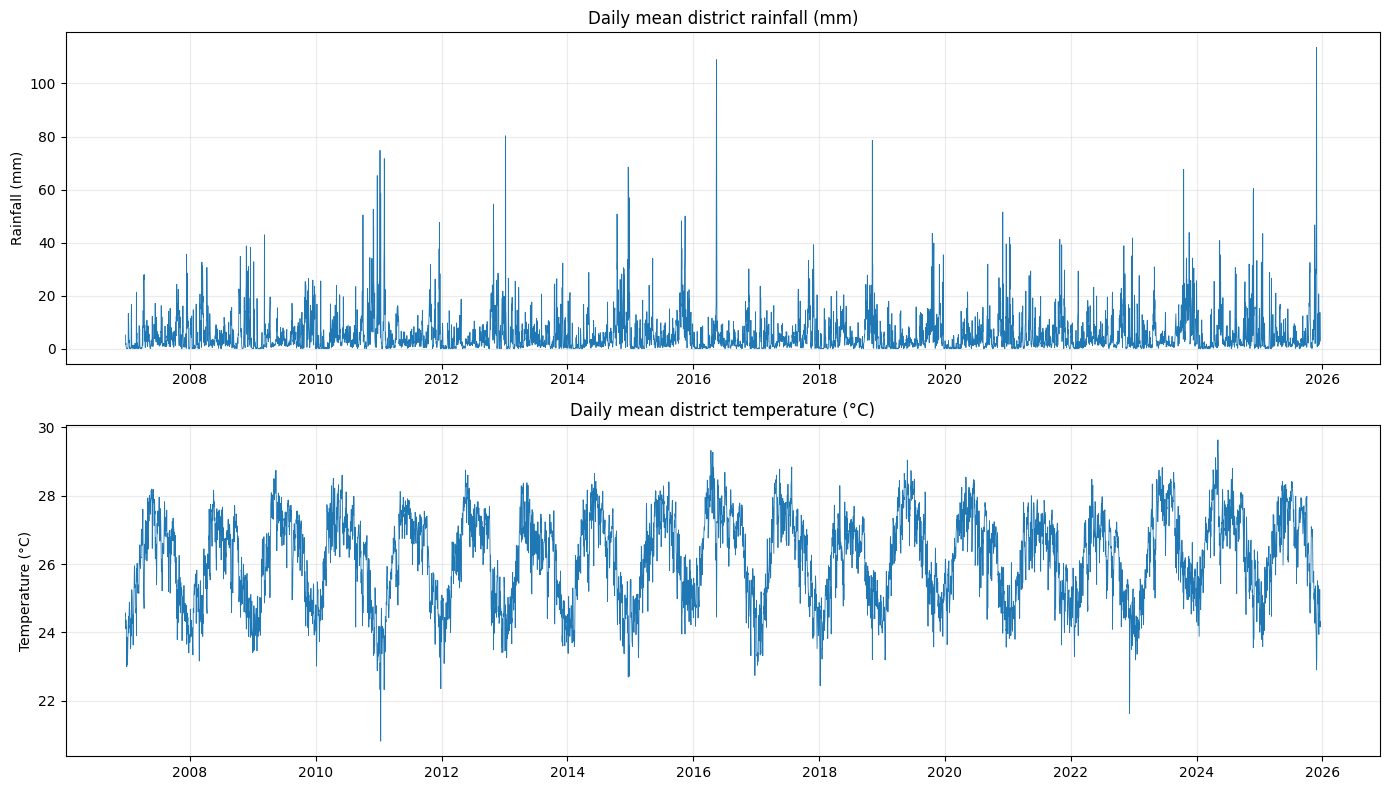

,count,mean,std,min,25%,50%,75%,max
precipitation_sum,173425.0,5.368927,10.407443,0.0,0.1,1.6,6.4,310.4
temperature_2m_mean,173425.0,26.184995,3.310329,8.5,25.4,26.6,28.1,32.9


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

daily_national = weather.groupby("date").agg(
    precipitation_mean=("precipitation_sum", "mean"),
    temperature_mean=("temperature_2m_mean", "mean")
)

axes[0].plot(daily_national.index, daily_national["precipitation_mean"], linewidth=0.6)
axes[0].set_title("Daily mean district rainfall (mm)")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].grid(alpha=0.25)

axes[1].plot(daily_national.index, daily_national["temperature_mean"], linewidth=0.6)
axes[1].set_title("Daily mean district temperature (°C)")
axes[1].set_ylabel("Temperature (°C)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

display(weather[TARGET_COLUMNS].describe().T)

## 7. Define forecast horizons and time split

In [7]:
HORIZONS = list(range(1, 8))
TRAIN_END = pd.Timestamp("2023-12-31")
VALIDATION_START = pd.Timestamp("2024-01-01")
VALIDATION_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")
TEST_END = pd.Timestamp("2025-12-31")

print("Training target dates: through", TRAIN_END.date())
print("Validation target dates:", VALIDATION_START.date(), "to", VALIDATION_END.date())
print("Test target dates:", TEST_START.date(), "to", TEST_END.date())

Training target dates: through 2023-12-31
Validation target dates: 2024-01-01 to 2024-12-31
Test target dates: 2025-01-01 to 2025-12-31


## 8. Feature engineering — information available at forecast origin

In [8]:
# Predictors are historical weather measurements. Every predictor is shifted
# by at least one day within each district so that the value for origin date t
# never uses weather observed after t-1.
BASE_WEATHER_FEATURES = [
    c for c in [
        "precipitation_sum",
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "relative_humidity_2m_mean",
        "relative_humidity_2m_max",
        "relative_humidity_2m_min",
        "dew_point_2m_mean",
        "wind_speed_10m_mean",
        "wind_speed_10m_max",
        "cloud_cover_mean",
        "shortwave_radiation_sum",
        "et0_fao_evapotranspiration"
    ]
    if c in weather.columns
]

feature_df = weather[["district", "date"] + BASE_WEATHER_FEATURES].copy()
feature_df = feature_df.sort_values(["district", "date"]).reset_index(drop=True)

grouped = feature_df.groupby("district", sort=False)

for col in BASE_WEATHER_FEATURES:
    for lag in [1, 2, 3, 7, 14, 28]:
        feature_df[f"{col}_lag_{lag}"] = grouped[col].shift(lag)

# Trailing means are shifted first: they use only dates before the origin date.
for col in ["precipitation_sum", "temperature_2m_mean"]:
    shifted = feature_df.groupby("district", sort=False)[col].shift(1)
    for window in [7, 14, 30]:
        feature_df[f"{col}_rolling_mean_{window}"] = (
            shifted.groupby(feature_df["district"]).transform(
                lambda s: s.rolling(window, min_periods=max(3, window // 2)).mean()
            )
        )

# Origin-date calendar features.
feature_df["origin_dayofyear_sin"] = np.sin(
    2 * np.pi * feature_df["date"].dt.dayofyear / 365.25
)
feature_df["origin_dayofyear_cos"] = np.cos(
    2 * np.pi * feature_df["date"].dt.dayofyear / 365.25
)
feature_df["origin_dayofweek"] = feature_df["date"].dt.dayofweek

print("Feature rows:", feature_df.shape[0])
print("Base weather variables:", BASE_WEATHER_FEATURES)

Feature rows: 173425
Base weather variables: ['precipitation_sum', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'cloud_cover_mean', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration']


## 9. Create direct target datasets for horizons 1–7

In [9]:
# Each row represents a forecast origin date. Target is the weather value
# at origin date + horizon. Target date is used only for splitting/evaluation
# and calendar features, never as a predictor.
target_lookup = weather.set_index(["district", "date"])[TARGET_COLUMNS]

dataset_by_target = {}
for target in TARGET_COLUMNS:
    for horizon in HORIZONS:
        frame = feature_df.copy()
        frame["target_date"] = frame["date"] + pd.to_timedelta(horizon, unit="D")
        keys = pd.MultiIndex.from_arrays(
            [frame["district"].values, frame["target_date"].values],
            names=["district", "date"]
        )
        frame["y"] = target_lookup.reindex(keys).to_numpy()
        frame["target_dayofyear_sin"] = np.sin(
            2 * np.pi * frame["target_date"].dt.dayofyear / 365.25
        )
        frame["target_dayofyear_cos"] = np.cos(
            2 * np.pi * frame["target_date"].dt.dayofyear / 365.25
        )
        frame["target_month"] = frame["target_date"].dt.month
        frame = frame.dropna(subset=["y"]).reset_index(drop=True)
        dataset_by_target[(target, horizon)] = frame

print("Created target datasets:", len(dataset_by_target))
for key, frame in list(dataset_by_target.items())[:3]:
    print(key, frame.shape, frame["target_date"].min(), frame["target_date"].max())

ValueError: Expected a 1D array, got an array with shape (173425, 2)

## 10. Define leakage-safe feature columns

In [ ]:
EXCLUDED_COLUMNS = {
    "date", "target_date", "y"
}
FEATURE_COLUMNS = [
    c for c in feature_df.columns
    if c not in ["date"]
] + [
    "target_dayofyear_sin",
    "target_dayofyear_cos",
    "target_month"
]
CATEGORICAL_FEATURES = ["district"]
NUMERIC_FEATURES = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_FEATURES]

print("Total predictors:", len(FEATURE_COLUMNS))
print("Categorical:", CATEGORICAL_FEATURES)
print("Numeric predictor count:", len(NUMERIC_FEATURES))

## 11. Candidate models

In [ ]:
# XGBoost is optional. If unavailable, the notebook continues with the
# persistence baseline, Random Forest and HistGradientBoosting.
try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed; three candidate approaches will be compared.")

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
    ])

def build_model(model_name):
    if model_name == "RandomForest":
        estimator = RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            max_features=0.8,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )
    elif model_name == "HistGradientBoosting":
        # HistGradientBoosting does not accept sparse one-hot output.
        estimator = HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE
        )
        # Use pandas category codes for district for this estimator.
        return estimator
    elif model_name == "XGBoost":
        estimator = XGBRegressor(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="reg:squarederror",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )
    else:
        raise ValueError(model_name)

    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", estimator)
    ])

MODEL_NAMES = ["Persistence", "RandomForest", "HistGradientBoosting"]
if XGBOOST_AVAILABLE:
    MODEL_NAMES.append("XGBoost")

print("Models to compare:", MODEL_NAMES)

## 12. Helper functions for features, baseline and metrics

In [ ]:
def model_matrix(frame, model_name):
    X = frame[FEATURE_COLUMNS].copy()
    if model_name == "HistGradientBoosting":
        X["district"] = X["district"].astype("category").cat.codes
        return X
    return X

def fit_predict(model_name, train_frame, predict_frame):
    if model_name == "Persistence":
        # Last observed value before forecast origin.
        # For h=1 this is origin-date value; use target variable lag-1.
        return predict_frame["persistence_value"].to_numpy()

    X_train = model_matrix(train_frame, model_name)
    X_predict = model_matrix(predict_frame, model_name)
    model = build_model(model_name)
    model.fit(X_train, train_frame["y"])
    return model.predict(X_predict), model

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

def add_persistence_feature(frame, target):
    # Latest observed value of the target at the forecast origin.
    lag_col = f"{target}_lag_1"
    if lag_col not in frame.columns:
        raise ValueError(f"Missing persistence feature: {lag_col}")
    frame = frame.copy()
    frame["persistence_value"] = frame[lag_col]
    return frame

## 13. Compare candidates on validation data

In [ ]:
validation_records = []
validation_predictions = {}

for target in TARGET_COLUMNS:
    for horizon in HORIZONS:
        frame = dataset_by_target[(target, horizon)]
        train_frame = frame[frame["target_date"] <= TRAIN_END].copy()
        val_frame = frame[
            (frame["target_date"] >= VALIDATION_START) &
            (frame["target_date"] <= VALIDATION_END)
        ].copy()

        train_frame = add_persistence_feature(train_frame, target)
        val_frame = add_persistence_feature(val_frame, target)

        # Ensure the model has usable training and validation examples.
        train_frame = train_frame.dropna(subset=["persistence_value"])
        val_frame = val_frame.dropna(subset=["persistence_value"])

        if train_frame.empty or val_frame.empty:
            print(f"Skipping {target}, horizon {horizon}: insufficient rows.")
            continue

        for model_name in MODEL_NAMES:
            if model_name == "Persistence":
                predictions = val_frame["persistence_value"].to_numpy()
            else:
                result = fit_predict(model_name, train_frame, val_frame)
                predictions, _ = result

            metrics = calculate_metrics(val_frame["y"], predictions)
            validation_records.append({
                "target": target,
                "horizon_days": horizon,
                "model": model_name,
                **metrics,
                "validation_rows": len(val_frame)
            })

            validation_predictions[(target, horizon, model_name)] = (
                val_frame[["district", "target_date", "y"]].assign(
                    prediction=predictions
                )
            )

validation_results = pd.DataFrame(validation_records)
display(validation_results.sort_values(["target", "MAE", "horizon_days"]))

validation_results.to_csv(
    FORECAST_OUTPUT_DIR / "weather_model_validation_comparison.csv",
    index=False
)
print("Validation comparison saved.")

## 14. Select the best model separately for each target

In [ ]:
# Selection criterion: lowest mean validation MAE across horizons 1–7.
# The 2025 test set is not consulted during selection.
selection_summary = (
    validation_results.groupby(["target", "model"], as_index=False)
    .agg(mean_validation_MAE=("MAE", "mean"),
         mean_validation_RMSE=("RMSE", "mean"),
         mean_validation_R2=("R2", "mean"))
)

selected_models = {}
for target in TARGET_COLUMNS:
    target_summary = selection_summary[
        selection_summary["target"] == target
    ].sort_values("mean_validation_MAE")
    if target_summary.empty:
        raise RuntimeError(f"No validation results available for {target}.")
    selected_models[target] = target_summary.iloc[0]["model"]

display(selection_summary.sort_values(["target", "mean_validation_MAE"]))
print("Selected models:", selected_models)

selection_summary.to_csv(
    FORECAST_OUTPUT_DIR / "weather_model_selection_summary.csv",
    index=False
)
with open(FORECAST_OUTPUT_DIR / "selected_weather_models.json", "w") as f:
    json.dump(selected_models, f, indent=4)

## 15. Evaluate selected models on the untouched 2025 test period

In [ ]:
test_records = []
test_predictions = {}

for target in TARGET_COLUMNS:
    selected_name = selected_models[target]

    for horizon in HORIZONS:
        frame = dataset_by_target[(target, horizon)]
        trainval_frame = frame[frame["target_date"] <= VALIDATION_END].copy()
        test_frame = frame[
            (frame["target_date"] >= TEST_START) &
            (frame["target_date"] <= TEST_END)
        ].copy()

        trainval_frame = add_persistence_feature(trainval_frame, target)
        test_frame = add_persistence_feature(test_frame, target)
        trainval_frame = trainval_frame.dropna(subset=["persistence_value"])
        test_frame = test_frame.dropna(subset=["persistence_value"])

        if trainval_frame.empty or test_frame.empty:
            print(f"Skipping test: {target}, horizon {horizon}")
            continue

        if selected_name == "Persistence":
            predictions = test_frame["persistence_value"].to_numpy()
        else:
            result = fit_predict(selected_name, trainval_frame, test_frame)
            predictions, _ = result

        metrics = calculate_metrics(test_frame["y"], predictions)
        test_records.append({
            "target": target,
            "horizon_days": horizon,
            "selected_model": selected_name,
            **metrics,
            "test_rows": len(test_frame)
        })

        test_predictions[(target, horizon)] = test_frame[
            ["district", "date", "target_date", "y"]
        ].assign(prediction=predictions)

test_results = pd.DataFrame(test_records)
display(test_results)

test_results.to_csv(
    FORECAST_OUTPUT_DIR / "weather_selected_models_test_metrics.csv",
    index=False
)

if test_predictions:
    test_prediction_df = pd.concat(
        [
            df.assign(target=key[0], horizon_days=key[1])
            for key, df in test_predictions.items()
        ],
        ignore_index=True
    )
    test_prediction_df.to_csv(
        FORECAST_OUTPUT_DIR / "weather_selected_models_test_predictions.csv",
        index=False
    )

print("Unseen test evaluation saved.")

## 16. Test-period diagnostic plots

In [ ]:
for target in TARGET_COLUMNS:
    target_test = test_results[test_results["target"] == target]
    if target_test.empty:
        continue

    plt.figure(figsize=(9, 5))
    plt.plot(target_test["horizon_days"], target_test["MAE"], marker="o", label="MAE")
    plt.plot(target_test["horizon_days"], target_test["RMSE"], marker="s", label="RMSE")
    plt.xlabel("Forecast horizon (days)")
    plt.ylabel("Error")
    plt.title(f"Unseen 2025 test errors — {target}")
    plt.xticks(HORIZONS)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    safe_target = target.replace("/", "_")
    plt.savefig(
        FORECAST_OUTPUT_DIR / f"{safe_target}_test_error_by_horizon.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

## 17. Rainfall-specific evaluation

In [ ]:
# Rainfall is often zero-inflated. Report metrics for all test days and
# separately for days with observed rainfall > 0. The latter is a diagnostic,
# not a separate model-selection criterion.
rainfall_diagnostics = []

for horizon in HORIZONS:
    key = ("precipitation_sum", horizon)
    if key not in test_predictions:
        continue

    df = test_predictions[key]
    wet = df[df["y"] > 0]

    rainfall_diagnostics.append({
        "horizon_days": horizon,
        "all_day_MAE": mean_absolute_error(df["y"], df["prediction"]),
        "wet_day_count": len(wet),
        "wet_day_MAE": (
            mean_absolute_error(wet["y"], wet["prediction"])
            if len(wet) else np.nan
        ),
        "observed_wet_day_frequency_percent": (df["y"] > 0).mean() * 100
    })

rainfall_diagnostics_df = pd.DataFrame(rainfall_diagnostics)
display(rainfall_diagnostics_df)

rainfall_diagnostics_df.to_csv(
    FORECAST_OUTPUT_DIR / "rainfall_test_diagnostics.csv",
    index=False
)

## 18. Refit selected model families on all available history

In [ ]:
# These deployment models are refitted using all available historical
# target observations. Their performance must be reported using the separate
# untouched-test results above, not their in-sample fit.
deployment_models = {}

for target in TARGET_COLUMNS:
    selected_name = selected_models[target]
    deployment_models[target] = {}

    for horizon in HORIZONS:
        frame = dataset_by_target[(target, horizon)].copy()
        frame = add_persistence_feature(frame, target)
        frame = frame.dropna(subset=["y", "persistence_value"])

        if selected_name == "Persistence":
            deployment_models[target][horizon] = None
            continue

        X = model_matrix(frame, selected_name)
        model = build_model(selected_name)
        model.fit(X, frame["y"])
        deployment_models[target][horizon] = model

        model_path = MODEL_OUTPUT_DIR / f"{target}_h{horizon}_{selected_name}.joblib"
        joblib.dump(model, model_path)

print("Deployment model refitting completed.")
print("Models saved in:", MODEL_OUTPUT_DIR)

## 19. Generate the next 1–7 daily forecasts for all districts

In [ ]:
# Forecast origin is the latest date for which observations are present
# for every district. Each horizon model uses the same origin-date features.
district_latest_dates = weather.groupby("district")["date"].max()
common_origin = district_latest_dates.min()

origin_rows = feature_df[feature_df["date"] == common_origin].copy()
expected_districts = sorted(weather["district"].unique())
available_districts = sorted(origin_rows["district"].unique())

if available_districts != expected_districts:
    raise ValueError(
        "Not every district has data on the common forecast origin. "
        "Inspect daily date continuity before generating forecasts."
    )

operational_forecasts = []

for target in TARGET_COLUMNS:
    selected_name = selected_models[target]

    for horizon in HORIZONS:
        origin_frame = origin_rows.copy()
        origin_frame["target_dayofyear_sin"] = np.sin(
            2 * np.pi * (origin_frame["date"] + pd.to_timedelta(horizon, unit="D")).dt.dayofyear / 365.25
        )
        origin_frame["target_dayofyear_cos"] = np.cos(
            2 * np.pi * (origin_frame["date"] + pd.to_timedelta(horizon, unit="D")).dt.dayofyear / 365.25
        )
        origin_frame["target_month"] = (
            origin_frame["date"] + pd.to_timedelta(horizon, unit="D")
        ).dt.month

        if selected_name == "Persistence":
            predictions = origin_frame[f"{target}_lag_1"].to_numpy()
        else:
            X_origin = model_matrix(origin_frame, selected_name)
            predictions = deployment_models[target][horizon].predict(X_origin)

        # Rainfall cannot be physically negative.
        if target == "precipitation_sum":
            predictions = np.maximum(predictions, 0)

        for district, prediction in zip(origin_frame["district"], predictions):
            operational_forecasts.append({
                "district": district,
                "forecast_origin_date": common_origin.date().isoformat(),
                "forecast_target_date": (
                    common_origin + pd.Timedelta(days=horizon)
                ).date().isoformat(),
                "horizon_days": horizon,
                "target": target,
                "predicted_value": float(prediction),
                "unit": "mm" if target == "precipitation_sum" else "degC",
                "selected_model": selected_name
            })

operational_forecast_df = pd.DataFrame(operational_forecasts)
display(operational_forecast_df.head(14))

operational_forecast_df.to_csv(
    FORECAST_OUTPUT_DIR / "daily_weather_forecast_next_7_days.csv",
    index=False
)

print("Forecast origin:", common_origin.date())
print("Forecast rows:", len(operational_forecast_df))
print("Forecast saved.")

## 20. Create a forecast chart for a selected district

In [ ]:
# Change the district name to any district present in the dataset.
SELECTED_DISTRICT = "Colombo"

district_forecast = operational_forecast_df[
    operational_forecast_df["district"].str.lower()
    == SELECTED_DISTRICT.lower()
]

if district_forecast.empty:
    print("District not found. Available districts:", expected_districts)
else:
    fig, axes = plt.subplots(2, 1, figsize=(11, 8))

    for target, axis, title, ylabel in [
        ("precipitation_sum", axes[0], "7-day rainfall forecast", "Rainfall (mm)"),
        ("temperature_2m_mean", axes[1], "7-day mean temperature forecast", "Temperature (°C)")
    ]:
        subset = district_forecast[district_forecast["target"] == target]
        axis.plot(
            pd.to_datetime(subset["forecast_target_date"]),
            subset["predicted_value"],
            marker="o"
        )
        axis.set_title(f"{SELECTED_DISTRICT} — {title}")
        axis.set_ylabel(ylabel)
        axis.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        FORECAST_OUTPUT_DIR / f"{SELECTED_DISTRICT.lower()}_7_day_weather_forecast.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

## 21. Final validation and run manifest

In [ ]:
# Validate forecast output dimensions and values.
expected_rows = weather["district"].nunique() * len(HORIZONS) * len(TARGET_COLUMNS)

checks = {
    "forecast_file_exists": (
        FORECAST_OUTPUT_DIR / "daily_weather_forecast_next_7_days.csv"
    ).exists(),
    "expected_forecast_row_count": len(operational_forecast_df) == expected_rows,
    "all_districts_present": (
        operational_forecast_df["district"].nunique() == weather["district"].nunique()
    ),
    "all_horizons_present": set(operational_forecast_df["horizon_days"]) == set(HORIZONS),
    "both_targets_present": set(operational_forecast_df["target"]) == set(TARGET_COLUMNS),
    "no_missing_predictions": operational_forecast_df["predicted_value"].notna().all(),
    "no_negative_rainfall_predictions": (
        operational_forecast_df.loc[
            operational_forecast_df["target"] == "precipitation_sum",
            "predicted_value"
        ].ge(0).all()
    )
}

for name, passed in checks.items():
    print(f"{name}: {passed}")

if not all(checks.values()):
    raise AssertionError("One or more final validation checks failed.")

manifest = {
    "source_file": str(DAILY_WEATHER_PATH),
    "source_min_date": weather["date"].min().date().isoformat(),
    "source_max_date": weather["date"].max().date().isoformat(),
    "district_count": int(weather["district"].nunique()),
    "forecast_origin": common_origin.date().isoformat(),
    "horizons_days": HORIZONS,
    "targets": TARGET_COLUMNS,
    "selected_models": selected_models,
    "training_target_end": TRAIN_END.date().isoformat(),
    "validation_period": [VALIDATION_START.date().isoformat(), VALIDATION_END.date().isoformat()],
    "unseen_test_period": [TEST_START.date().isoformat(), TEST_END.date().isoformat()],
    "validation_selection_metric": "mean MAE across horizons 1-7",
    "test_metrics_file": "weather_selected_models_test_metrics.csv",
    "operational_forecast_file": "daily_weather_forecast_next_7_days.csv",
    "limitations": [
        "ERA5 is reanalysis data, not an operational future weather forecast feed.",
        "Operational forecasts from this statistical model require prospective validation.",
        "Rainfall forecasts are clipped at zero.",
        "The 2025 test period is not used for model selection."
    ]
}

with open(FORECAST_OUTPUT_DIR / "weather_forecasting_manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("\nNOTEBOOK 15 FINAL VALIDATION PASSED")
print("Outputs:", FORECAST_OUTPUT_DIR)

## 22. Interpretation and reporting checklist

Before reporting results, review:

1. Which model was selected for rainfall?
2. Which model was selected for temperature?
3. How do MAE and RMSE change from horizon 1 to horizon 7?
4. Does the selected model outperform the persistence baseline on the unseen 2025 test period?
5. How does rainfall performance differ on wet days and all days?
6. Are any districts missing dates or forecast rows?
7. Are predictions plausible and are units correct?

Do not claim the weather forecasts are operationally reliable solely because a model produced seven-day predictions. Compare them prospectively against an operational numerical weather prediction source and newly observed weather when available.

### Outputs
All outputs are saved under `outputs/weather_forecasting/`, with trained model files under `outputs/weather_forecasting/models/`.
